# Heart — Paper replication

This notebook replicates the analysis described by Khanna et al., *Comparative Study of Classification Techniques (SVM, Logistic Regression and Neural Networks) to Predict the Prevalence of Heart Disease*, DOI: [10.7763/IJMLC.2015.V5.544](https://doi.org/10.7763/IJMLC.2015.V5.544).

It compares logistic regression and SVM configurations using 5-fold and 10-fold cross-validation, alongside backpropagation, RBF and GRNN models. Results include performance tables and ROC comparisons.

The implementation uses a stratified 50/50 split with training-fitted standardisation. Standardisation is performed before internal cross-validation and is not refitted within each fold.

Test-performance rankings are descriptive. The 10-fold L2 logistic-regression variant is pre-specified separately for the XAI extension.

In [ ]:
import os

os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import (
    accuracy_score,
    auc,
    f1_score,
    roc_curve,
)
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import SGD

In [ ]:

file_path = "../../data/heart/processed.cleveland.data"

# Define the source dataset columns.
column_names = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs',
    'restecg', 'thalach', 'exang', 'oldpeak',
    'slope', 'ca', 'thal', 'target'
]

df = pd.read_csv(file_path, names=column_names)

# Replace the source missing-value marker.
df.replace('?', np.nan, inplace=True)

# Convert the source columns to numeric values.
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Remove incomplete observations.
df = df.dropna()

# Convert the diagnosis to a binary outcome.
df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

X = df.drop('target', axis=1)
y = df['target']

feature_names = X.columns.tolist()

# The source paper uses equal training and test subsets. Split before
# learning preprocessing parameters to prevent test-data leakage.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.50,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train = pd.DataFrame(
    scaler.fit_transform(X_train_raw),
    columns=feature_names,
    index=X_train_raw.index,
)
X_test = pd.DataFrame(
    scaler.transform(X_test_raw),
    columns=feature_names,
    index=X_test_raw.index,
)

In [ ]:
lr_5fold = LogisticRegressionCV(Cs=10, cv=5, penalty='l2', solver='liblinear', max_iter=1000, random_state=42)
lr_10fold = LogisticRegressionCV(Cs=10, cv=10, penalty='l2', solver='liblinear', max_iter=1000, random_state=42)

lr_5fold.fit(X_train, y_train)
lr_10fold.fit(X_train, y_train)

y_pred_lr_5fold = lr_5fold.predict(X_test)
y_pred_lr_10fold = lr_10fold.predict(X_test)

print("Logistic Regression (5-fold CV) Test Accuracy:", accuracy_score(y_test, y_pred_lr_5fold))
print("Logistic Regression (5-fold CV) F1 Score:", f1_score(y_test, y_pred_lr_5fold))
print("Logistic Regression (10-fold CV) Test Accuracy:", accuracy_score(y_test, y_pred_lr_10fold))
print("Logistic Regression (10-fold CV) F1 Score:", f1_score(y_test, y_pred_lr_10fold))

Logistic Regression (5-fold CV) Test Accuracy: 0.8523489932885906
Logistic Regression (5-fold CV) F1 Score: 0.8405797101449275
Logistic Regression (10-fold CV) Test Accuracy: 0.8523489932885906
Logistic Regression (10-fold CV) F1 Score: 0.8405797101449275


In [ ]:
y_score_lr = lr_10fold.predict_proba(X_test)[:, 1]

fpr_lr, tpr_lr, _ = roc_curve(
    y_test,
    y_score_lr
)

auc_lr = auc(
    fpr_lr,
    tpr_lr
)

print(
    f"Logistic Regression AUC: {auc_lr:.2f}"
)

Logistic Regression AUC: 0.92


In [ ]:
print("Unique values in y_train:", np.unique(y_train))
print("Unique values in y_test:", np.unique(y_test))
print("Missing values in y_train:", y_train.isnull().sum())
print("Missing values in y_test:", y_test.isnull().sum())

Unique values in y_train: [0 1]
Unique values in y_test: [0 1]
Missing values in y_train: 0
Missing values in y_test: 0


In [ ]:
param_grid_linear = {
    'C': [0.1, 1, 10],
    'kernel': ['linear']
}

param_grid_rbf = {
    'C': [1, 10],
    'gamma': [0.1, 0.01],
    'kernel': ['rbf']
}

param_grid_poly = {
    'C': [1, 10],
    'gamma': ['scale'],
    'degree': [2, 3],
    'kernel': ['poly']
}

In [ ]:
svm_linear_5 = GridSearchCV(
    SVC(probability=True),
    param_grid_linear,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

svm_linear_5.fit(X_train, y_train)

y_train_pred_linear_5 = svm_linear_5.predict(X_train)
y_test_pred_linear_5 = svm_linear_5.predict(X_test)

svm_linear_10 = GridSearchCV(
    SVC(probability=True),
    param_grid_linear,
    cv=10,
    scoring='accuracy',
    n_jobs=-1
)

svm_linear_10.fit(X_train, y_train)

y_train_pred_linear_10 = svm_linear_10.predict(X_train)
y_test_pred_linear_10 = svm_linear_10.predict(X_test)

In [ ]:
svm_rbf_5 = GridSearchCV(
    SVC(probability=True),
    param_grid_rbf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

svm_rbf_5.fit(X_train, y_train)

y_train_pred_rbf_5 = svm_rbf_5.predict(X_train)
y_test_pred_rbf_5 = svm_rbf_5.predict(X_test)

svm_rbf_10 = GridSearchCV(
    SVC(probability=True),
    param_grid_rbf,
    cv=10,
    scoring='accuracy',
    n_jobs=-1
)

svm_rbf_10.fit(X_train, y_train)

y_train_pred_rbf_10 = svm_rbf_10.predict(X_train)
y_test_pred_rbf_10 = svm_rbf_10.predict(X_test)

In [ ]:
svm_poly_5 = GridSearchCV(
    SVC(probability=True),
    param_grid_poly,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

svm_poly_5.fit(X_train, y_train)

y_train_pred_poly_5 = svm_poly_5.predict(X_train)
y_test_pred_poly_5 = svm_poly_5.predict(X_test)

svm_poly_10 = GridSearchCV(
    SVC(probability=True),
    param_grid_poly,
    cv=10,
    scoring='accuracy',
    n_jobs=-1
)

svm_poly_10.fit(X_train, y_train)

y_train_pred_poly_10 = svm_poly_10.predict(X_train)
y_test_pred_poly_10 = svm_poly_10.predict(X_test)

In [ ]:
results = []

def add_result(model, kernel, cv, params, y_train, y_train_pred, y_test, y_test_pred):
    """Append one fitted model's summary metrics to the shared results list.

    Args:
        model: Display name for the fitted model family.
        kernel: Kernel or model variant recorded for the comparison.
        cv: Cross-validation setting associated with the model.
        params: Hyperparameter mapping recorded with the result.
        y_train: Observed training labels.
        y_train_pred: Predicted training labels.
        y_test: Observed held-out labels.
        y_test_pred: Predicted held-out labels.

    Returns:
        None. The module-level ``results`` list is updated in place.
    """
    results.append([
        model,
        kernel,
        cv,
        str(params),
        accuracy_score(y_test, y_test_pred) * 100,
        accuracy_score(y_train, y_train_pred) * 100,
        f1_score(y_test, y_test_pred)
    ])

add_result("SVM", "LINEAR", "5-FOLD", svm_linear_5.best_params_, y_train, y_train_pred_linear_5, y_test, y_test_pred_linear_5)
add_result("SVM", "LINEAR", "10-FOLD", svm_linear_10.best_params_, y_train, y_train_pred_linear_10, y_test, y_test_pred_linear_10)

add_result("SVM", "RBF", "5-FOLD", svm_rbf_5.best_params_, y_train, y_train_pred_rbf_5, y_test, y_test_pred_rbf_5)
add_result("SVM", "RBF", "10-FOLD", svm_rbf_10.best_params_, y_train, y_train_pred_rbf_10, y_test, y_test_pred_rbf_10)

add_result("SVM", "POLY", "5-FOLD", svm_poly_5.best_params_, y_train, y_train_pred_poly_5, y_test, y_test_pred_poly_5)
add_result("SVM", "POLY", "10-FOLD", svm_poly_10.best_params_, y_train, y_train_pred_poly_10, y_test, y_test_pred_poly_10)

add_result("LR", "NA", "5-FOLD", lr_5fold.get_params(), y_train, lr_5fold.predict(X_train), y_test, y_pred_lr_5fold)
add_result("LR", "NA", "10-FOLD", lr_10fold.get_params(), y_train, lr_10fold.predict(X_train), y_test, y_pred_lr_10fold)

results_df = pd.DataFrame(results, columns=[
    "MODEL",
    "KERNEL",
    "CV",
    "BEST PARAMS",
    "ACCURACY (TEST DATA) %",
    "ACCURACY (TRAIN DATA) %",
    "F1 SCORE"
])

results_df = results_df.round(2)

print(results_df)

  MODEL  KERNEL       CV                                        BEST PARAMS  \
0   SVM  LINEAR   5-FOLD                      {'C': 10, 'kernel': 'linear'}   
1   SVM  LINEAR  10-FOLD                      {'C': 10, 'kernel': 'linear'}   
2   SVM     RBF   5-FOLD           {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}   
3   SVM     RBF  10-FOLD           {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}   
4   SVM    POLY   5-FOLD  {'C': 10, 'degree': 3, 'gamma': 'scale', 'kern...   
5   SVM    POLY  10-FOLD  {'C': 10, 'degree': 3, 'gamma': 'scale', 'kern...   
6    LR      NA   5-FOLD  {'Cs': 10, 'class_weight': None, 'cv': 5, 'dua...   
7    LR      NA  10-FOLD  {'Cs': 10, 'class_weight': None, 'cv': 10, 'du...   

   ACCURACY (TEST DATA) %  ACCURACY (TRAIN DATA) %  F1 SCORE  
0                   83.89                    84.46      0.83  
1                   83.89                    84.46      0.83  
2                   85.91                    83.11      0.84  
3                   85.91           

networks

In [ ]:
y_train_np = np.array(y_train)
y_test_np = np.array(y_test)

model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(15, activation='sigmoid'))
model.add(Dense(1, activation='sigmoid'))

optimizer = SGD(learning_rate=0.01, momentum=0.1)

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.fit(X_train, y_train_np, epochs=50, batch_size=8, verbose=0)

y_pred_nn = (model.predict(X_test, verbose=0) > 0.5).astype(int)

y_train_pred_nn = (model.predict(X_train, verbose=0) > 0.5).astype(int)

bp_train_acc = accuracy_score(y_train_np, y_train_pred_nn)
bp_test_acc = accuracy_score(y_test_np, y_pred_nn)
bp_f1 = f1_score(y_test_np, y_pred_nn)

print("\nBackprop NN Accuracy:", bp_test_acc)
print("Backprop NN F1:", bp_f1)

y_scores_bp = model.predict(X_test, verbose=0).ravel()
fpr_bp, tpr_bp, _ = roc_curve(y_test_np, y_scores_bp)
auc_bp = auc(fpr_bp, tpr_bp)

print(f"Backprop NN AUC: {auc_bp:.2f}")


1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step



1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step



Backprop NN Accuracy: 0.8590604026845637
Backprop NN F1: 0.8444444444444444

1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


Backprop NN AUC: 0.92


In [ ]:
# X_train and X_test were already standardized using training-only
# parameters. Do not fit a second scaler.
X_train_scaled = X_train.to_numpy()
X_test_scaled = X_test.to_numpy()

kmeans = KMeans(n_clusters=15, random_state=42)
kmeans.fit(X_train_scaled)
centers = kmeans.cluster_centers_

sigma = 2.0

def rbf_transform(X, centers, sigmas):
    """Transform observations into Gaussian radial-basis features.

    Args:
        X: Observation matrix to transform.
        centers: Radial-basis centres in the original feature space.
        sigmas: Width parameters associated with the basis functions.

    Returns:
        A matrix of Gaussian responses for every observation-centre pair.
    """
    dists = cdist(X, centers)
    return np.exp(-(dists ** 2) / (sigmas ** 2))

X_train_rbf = rbf_transform(X_train_scaled, centers, sigma)
X_test_rbf = rbf_transform(X_test_scaled, centers, sigma)

rbf_model = LogisticRegression(penalty='l2', C=1.0, solver='liblinear', max_iter=1000)
rbf_model.fit(X_train_rbf, y_train)

y_pred_rbf = rbf_model.predict(X_test_rbf)
y_train_pred_rbf = rbf_model.predict(X_train_rbf)

rbf_train_acc = accuracy_score(y_train, y_train_pred_rbf)
rbf_test_acc = accuracy_score(y_test, y_pred_rbf)
rbf_f1 = f1_score(y_test, y_pred_rbf)

print(f"RBF Network Test Accuracy: {rbf_test_acc:.2f}")
print(f"RBF Network Train Accuracy: {rbf_train_acc:.2f}")
print(f"RBF Network F1-Score: {rbf_f1:.2f}")

W = np.linalg.pinv(X_train_rbf).dot(y_train) 
y_scores_rbf = X_test_rbf.dot(W) 
y_scores_rbf = (y_scores_rbf - y_scores_rbf.min()) / (y_scores_rbf.max() - y_scores_rbf.min()) 

fpr_rbf_nn, tpr_rbf_nn, _ = roc_curve(y_test, y_scores_rbf) 
auc_rbf_nn = auc(fpr_rbf_nn, tpr_rbf_nn)
print(f"RBF NN AUC: {auc_rbf_nn:.2f}")

RBF Network Test Accuracy: 0.76
RBF Network Train Accuracy: 0.78
RBF Network F1-Score: 0.67
RBF NN AUC: 0.65


In [ ]:
sigma = 1.3

def grnn_predict(X_train, y_train, X_test, sigma):
    """Generate GRNN scores for a set of observations.

    Args:
        X_train: Numeric training feature matrix.
        y_train: Binary training outcomes used as kernel-weighted targets.
        X_test: Numeric observations for which scores are required.
        sigma: Gaussian-kernel bandwidth.

    Returns:
        An array of continuous kernel-weighted prediction scores.
    """
    # DataFrames iterate over column labels; convert explicitly so the
    # GRNN always iterates over numeric observation rows.
    X_train_array = np.asarray(X_train, dtype=float)
    X_test_array = np.asarray(X_test, dtype=float)
    y_train_array = np.asarray(y_train, dtype=float)

    y_pred = []
    for x in X_test_array:
        distances = euclidean_distances(
            x.reshape(1, -1), X_train_array
        )[0]
        weights = np.exp(-(distances**2) / (2 * sigma**2))
        numerator = np.sum(weights * y_train_array)
        denominator = np.sum(weights)
        prediction = numerator / denominator
        y_pred.append(prediction)
    return np.array(y_pred)

y_scores_grnn_test = grnn_predict(X_train, y_train.values, X_test, sigma=sigma)
y_scores_grnn_train = grnn_predict(X_train, y_train.values, X_train, sigma=sigma)

y_pred_grnn = (y_scores_grnn_test > 0.5).astype(int)
y_train_pred_grnn = (y_scores_grnn_train > 0.5).astype(int)

grnn_acc = accuracy_score(y_test, y_pred_grnn)
grnn_train_acc = accuracy_score(y_train, y_train_pred_grnn)
grnn_f1 = f1_score(y_test, y_pred_grnn)

fpr_grnn, tpr_grnn, _ = roc_curve(y_test, y_scores_grnn_test)
auc_grnn = auc(fpr_grnn, tpr_grnn)

print(f"GRNN Network Test Accuracy: {grnn_acc:.2f}")
print(f"GRNN Network Train Accuracy: {grnn_train_acc:.2f}")
print(f"GRNN Network F1-Score: {grnn_f1:.2f}")
print(f"GRNN AUC: {auc_grnn:.2f}")

GRNN Network Test Accuracy: 0.87
GRNN Network Train Accuracy: 0.94
GRNN Network F1-Score: 0.85
GRNN AUC: 0.91


In [ ]:
nn_results = pd.DataFrame([
    ["BACKPROP", 15, "NA", bp_test_acc*100, bp_train_acc*100, bp_f1],
    ["RBF (K-MEANS)", 15, "NA", rbf_test_acc*100, rbf_train_acc*100, rbf_f1],
    ["GRNN", "NA", "1.3", grnn_acc*100, grnn_train_acc*100, grnn_f1]
],
columns=[
    "MODEL",
    "NO OF HIDDEN UNITS",
    "PARAMETERS",
    "ACCURACY (TEST DATA) %",
    "ACCURACY (TRAIN DATA) %",
    "F1-SCORE"
])

nn_results = nn_results.round(2)
print(nn_results)

           MODEL NO OF HIDDEN UNITS PARAMETERS  ACCURACY (TEST DATA) %  \
0       BACKPROP                 15         NA                   85.91   
1  RBF (K-MEANS)                 15         NA                   75.84   
2           GRNN                 NA        1.3                   86.58   

   ACCURACY (TRAIN DATA) %  F1-SCORE  
0                    83.78      0.84  
1                    78.38      0.67  
2                    93.92      0.85  


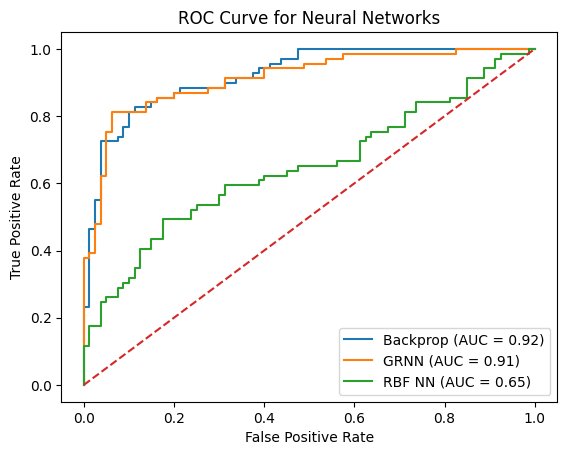

In [ ]:
plt.figure()
plt.plot(fpr_bp, tpr_bp, label=f"Backprop (AUC = {auc_bp:.2f})")
plt.plot(fpr_grnn, tpr_grnn, label=f"GRNN (AUC = {auc_grnn:.2f})")
plt.plot(fpr_rbf_nn, tpr_rbf_nn, label=f"RBF NN (AUC = {auc_rbf_nn:.2f})")
plt.plot([0, 1], [0, 1], '--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Neural Networks")
plt.legend()
plt.show()

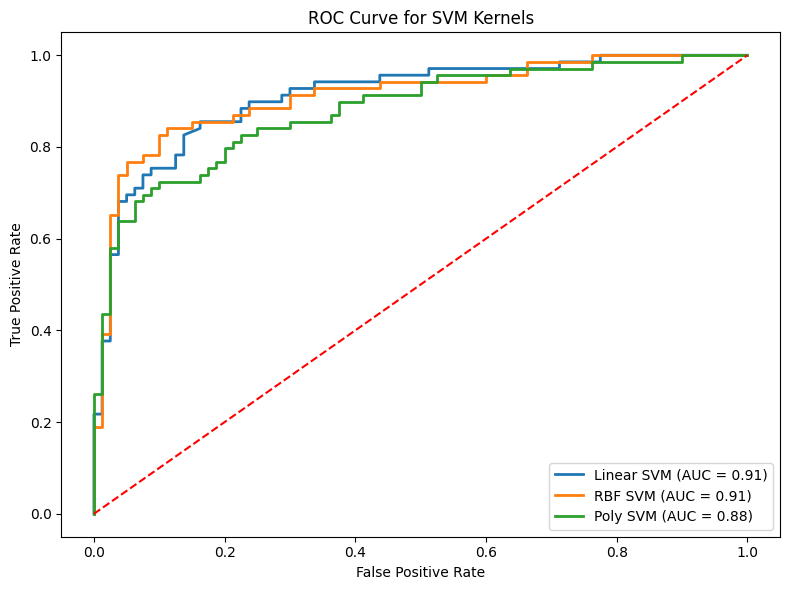

In [ ]:
best_svm_models = {
    "Linear SVM": svm_linear_10,
    "RBF SVM": svm_rbf_10,
    "Poly SVM": svm_poly_10
}

plt.figure(figsize=(8, 6))

auc_linear = None
auc_rbf = None
auc_poly = None

for label, svm_model in best_svm_models.items():

    y_score = svm_model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test,
        y_score
    )

    roc_auc = auc(
        fpr,
        tpr
    )

    if label == "Linear SVM":
        auc_linear = roc_auc

    elif label == "RBF SVM":
        auc_rbf = roc_auc

    elif label == "Poly SVM":
        auc_poly = roc_auc

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{label} (AUC = {roc_auc:.2f})"
    )

plt.plot([0, 1], [0, 1], 'r--', linewidth=1.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for SVM Kernels")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
all_models = {
    "LR_10fold": lr_10fold,
    "Linear_SVM": svm_linear_10.best_estimator_,
    "RBF_SVM": svm_rbf_10.best_estimator_,
    "Poly_SVM": svm_poly_10.best_estimator_,
    "Backprop_NN": model,
    "RBF_NN": rbf_model
}

In [ ]:
performance_df = pd.DataFrame({

    "Model": [

        "Logistic Regression",

        "Linear SVM",

        "RBF SVM",

        "Polynomial SVM",

        "Backprop NN",

        "RBF NN",

        "GRNN"
    ],

    "AUC": [

        auc_lr,

        auc_linear,

        auc_rbf,

        auc_poly,

        auc_bp,

        auc_rbf_nn,

        auc_grnn
    ]
})

performance_df = performance_df.sort_values(
    "AUC",
    ascending=False
)

print(performance_df)

                 Model       AUC
4          Backprop NN  0.921739
0  Logistic Regression  0.915217
6                 GRNN  0.913043
2              RBF SVM  0.911594
1           Linear SVM  0.911051
3       Polynomial SVM  0.880254
5               RBF NN  0.647826


In [ ]:
# This is a descriptive test-set comparison, not a model-selection step.
test_auc_leader = performance_df.iloc[0]["Model"]
print(f"Highest observed test AUC (descriptive only): {test_auc_leader}")

Highest observed test AUC (descriptive only): Backprop NN


## Interpretation

The procedural replication retained the broad source-study comparison but did not recover an identical ranking for every model. The backpropagation network produced the highest held-out ROC-AUC, while the GRNN produced the highest accuracy; the RBF neural-network implementation performed substantially worse. The logistic-regression configuration used later for XAI was pre-specified as a probabilistic, coefficient-based baseline and was not selected because it was the strongest model on this test partition.
